In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


In [3]:
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

In [4]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

In [5]:
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    augmentation,
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [6]:
cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history_cnn = cnn.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 30ms/step - accuracy: 0.9318 - loss: 0.2222 - val_accuracy: 0.9797 - val_loss: 0.0704
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.9767 - loss: 0.0742 - val_accuracy: 0.9863 - val_loss: 0.0439
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 30ms/step - accuracy: 0.9831 - loss: 0.0544 - val_accuracy: 0.9875 - val_loss: 0.0454
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9857 - loss: 0.0450 - val_accuracy: 0.9908 - val_loss: 0.0342
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 30ms/step - accuracy: 0.9875 - loss: 0.0395 - val_accuracy: 0.9908 - val_loss: 0.0355
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9883 - loss: 0.0342 - val_accuracy: 0.9903 - val_loss: 0.0352
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9911 - loss: 0.0292 - val_accuracy: 0.9902 - val_loss: 0.0401
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 14ms/step - accuracy: 0.9910 - loss: 0.0273 - 

In [8]:
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [9]:
mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
history_mlp = mlp.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.8882 - loss: 0.3770 - val_accuracy: 0.9628 - val_loss: 0.1380
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9479 - loss: 0.1759 - val_accuracy: 0.9700 - val_loss: 0.1028
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9587 - loss: 0.1349 - val_accuracy: 0.9753 - val_loss: 0.0882
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9650 - loss: 0.1155 - val_accuracy: 0.9798 - val_loss: 0.0735
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9699 - loss: 0.1003 - val_accuracy: 0.9738 - val_loss: 0.0960
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9725 - loss: 0.0929 - val_accuracy: 0.9777 - val_loss: 0.0784
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9731 - loss: 0.0862 - val_accuracy: 0.9812 - val_loss: 0.0678
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9749 - loss: 0.0811 - val_acc

In [11]:
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test)

print("\nCNN Test Accuracy:", cnn_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9930 - loss: 0.0233

CNN Test Accuracy: 0.9929999709129333


In [12]:
mlp_loss, mlp_acc = mlp.evaluate(x_test, y_test)

print("MLP Test Accuracy:", mlp_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9818 - loss: 0.0574
MLP Test Accuracy: 0.9818000197410583


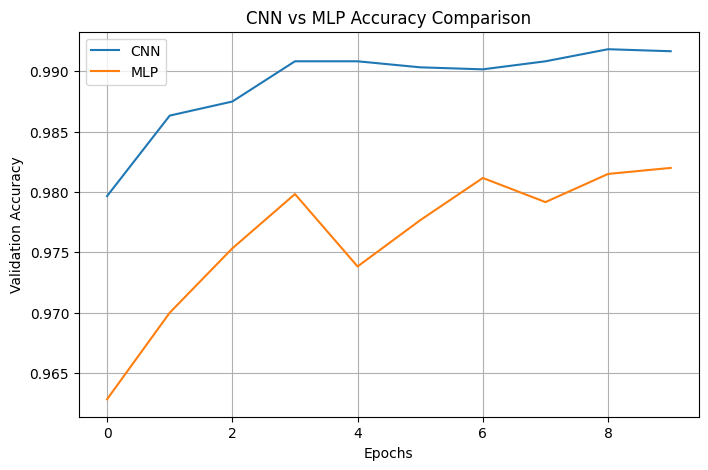

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['val_accuracy'], label='CNN')
plt.plot(history_mlp.history['val_accuracy'], label='MLP')

plt.title('CNN vs MLP Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

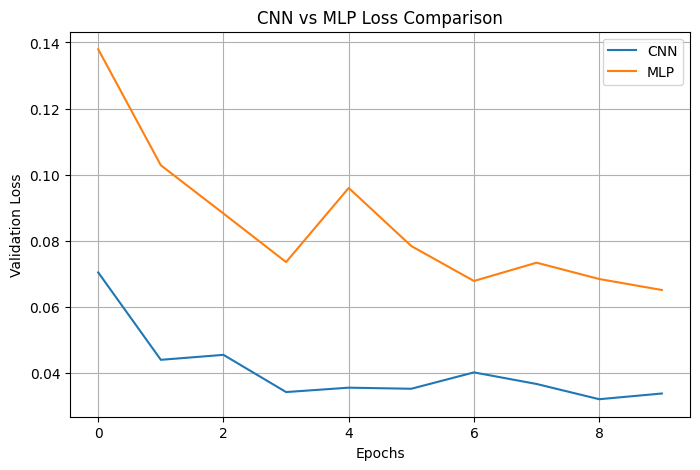

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['val_loss'], label='CNN')
plt.plot(history_mlp.history['val_loss'], label='MLP')

plt.title('CNN vs MLP Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid()
plt.show()

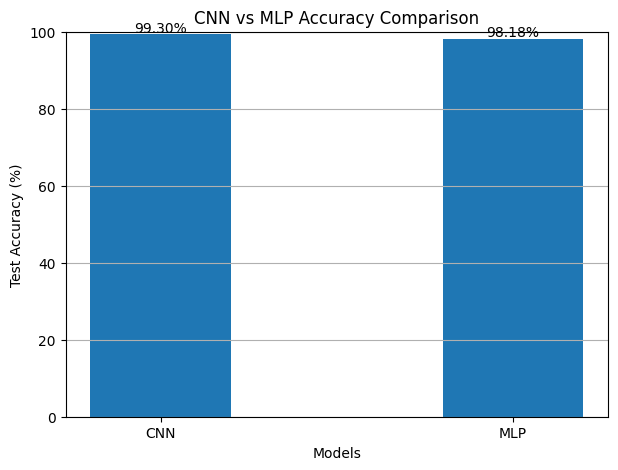

In [15]:
plt.figure(figsize=(7, 5))

models = ['CNN', 'MLP']
accuracy = [cnn_acc * 100, mlp_acc * 100]

plt.bar(models, accuracy, width=0.4)

plt.title('CNN vs MLP Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

for i, v in enumerate(accuracy):
    plt.text(i, v + 0.5, f'{v:.2f}%', ha='center')

plt.grid(axis='y')
plt.show()

In [16]:
print("\nFinal Performance Comparison")
print("CNN Accuracy:", round(cnn_acc * 100, 2), "%")
print("MLP Accuracy:", round(mlp_acc * 100, 2), "%")
print("CNN Loss:", round(cnn_loss, 4))
print("MLP Loss:", round(mlp_loss, 4))


Final Performance Comparison
CNN Accuracy: 99.3 %
MLP Accuracy: 98.18 %
CNN Loss: 0.0233
MLP Loss: 0.0574
